# Lab 01 — Exploratory Data Analysis

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

Part A is adapted from the *Python Data Science Handbook* by Jake VanderPlas
([book](http://shop.oreilly.com/product/0636920034919.do), [GitHub](https://github.com/jakevdp/PythonDataScienceHandbook));
text released under [CC-BY-NC-ND](https://creativecommons.org/licenses/by-nc-nd/3.0/us/legalcode), code under the [MIT license](https://opensource.org/licenses/MIT).

## Goal of this lab

Apply the **EDA checklist** of Lecture 6 in code, with the tools of Lecture 7.

| # | Checklist item | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Kind of data set; type of every column; identifiers out | A1 | B1 |
| 2 | Summaries and one plot per variable | A2 | B2 |
| 3 | Missing values: how many, and why | A3 | B3 |
| 4 | Codes, defaults, impossible values, outliers, duplicates | A3 | B3 |
| 5 | The target: balance | A4 | B4 |
| 6 | Each feature × target; correlations; confounders | A5 | B5 |
| 7 | Write down findings → preparation actions | A6 | B6 |

- **Part A (≈ 40 min)** — the Iris data set: small and clean, to learn the calls.
- **Part B (≈ 60 min)** — the NordicMart customer table seen in the lecture: real-looking problems, to practice the judgement.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices)

- Write code in the empty cells; write **answers and findings in markdown cells**, not in comments.
- Never modify the raw data: the raw tables are loaded once and **not changed**; every fix goes into a working copy.
- Before closing: **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors.

## Setup

All imports, paths and constants in one place. Adjust `DATA_DIR` if your data folder is somewhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../../data")                      # relative path: works on any machine
IRIS_FILE = DATA_DIR / "iris.csv"
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42                                          # fixed seed: same "random" results at every run

pd.set_option("display.precision", 2)
plt.rcParams["figure.figsize"] = (8, 4)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | numpy 2.5.4 | seaborn 0.13.2


# Part A — Iris

The [Iris data set](https://en.wikipedia.org/wiki/Iris_flower_data_set), analysed by Ronald Fisher in 1936:
measurements of 150 iris flowers of three species.
Your data folder contains two files, `iris.csv` and `iris.names`.

## A1. Kind of data set and type of every column

### Look at the raw file before loading it

Open `iris.csv` and `iris.names` as text (a text editor, or the cell below) and answer:

1. is it a `csv` file or something else?
2. what is the *separator* character (`,`, `;`, `\t`, ...)?
3. is there a *header*, i.e. a first row with the column names?
4. if there is no header, where can you find reasonable names? (for UCI data sets: the `.names` file)
5. is the data set supervised? which column is the *target*?

In [2]:
# the first lines of the file, as plain text
with open(IRIS_FILE) as f:
    for _ in range(5):
        print(f.readline(), end="")

5.1,3.5,1.4,0.2,Iris-setosa
4.9,3.0,1.4,0.2,Iris-setosa
4.7,3.2,1.3,0.2,Iris-setosa
4.6,3.1,1.5,0.2,Iris-setosa
5.0,3.6,1.4,0.2,Iris-setosa


## Answer
1. Yes.
2. The separator character is `,`.
3. No, there is no readable information in the header of data.
4. Find the column name in iris.name files `Attribute Information`.
5. `Yes, is's a supervised.` Since we can see there's class attribute in each data (row),

### Load the data set into a pandas `DataFrame`

- documentation: [`pd.read_csv()`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) — check how to give the column names when there is no header
- name the DataFrame `iris`; it is the raw table and **will not be modified**

In [3]:

names = ["sepal length", "sepal width", "petal length", "petal width", "class"]
iris = pd.read_csv(IRIS_FILE, header=None, names=names)

print(iris)

     sepal length  sepal width  petal length  petal width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


Show the column names, the number of rows and columns (attribute `shape`) and the type of each column (`dtypes`, or `info()`).
Then store the size of the data set in two variables, `n_samples` and `n_features`:

- each row is a single flower: a *sample*; the number of rows is `n_samples`
- each column that describes the samples is a *feature*; `class` is **not** a feature but the *target*, so `n_features` is the number of columns minus one

Why these two names? They are the standard vocabulary of scikit-learn: from the next labs on, every model expects the features
as a table of shape `(n_samples, n_features)` and the target as a column of length `n_samples`, and you will read these names
in every docstring. Separating features from target (and, in Part B, from identifiers) is the first decision of any analysis.

In [4]:
print(iris.columns.to_list())
print(f"There are { iris.shape[0] } rows and { iris.shape[1] } columns.")

n_samples, n_features = iris.shape
n_features -= 1

print( f"n_samples = { n_samples }, n_features = { n_features } (+ 1 target column)" )

iris.info()


['sepal length', 'sepal width', 'petal length', 'petal width', 'class']
There are 150 rows and 5 columns.
n_samples = 150, n_features = 4 (+ 1 target column)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal length  150 non-null    float64
 1   sepal width   150 non-null    float64
 2   petal length  150 non-null    float64
 3   petal width   150 non-null    float64
 4   class         150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


Show the first rows with `head()`, then a random sample of rows with `sample(5)`.
Run the `sample` cell twice: what happens? Then add `random_state=SEED` and run it twice again.

In [5]:
iris.head()


,sepal length,sepal width,petal length,petal width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
iris.sample(5, random_state=SEED)

,sepal length,sepal width,petal length,petal width,class
73,6.1,2.8,4.7,1.2,Iris-versicolor
18,5.7,3.8,1.7,0.3,Iris-setosa
118,7.7,2.6,6.9,2.3,Iris-virginica
78,6.0,2.9,4.5,1.5,Iris-versicolor
76,6.8,2.8,4.8,1.4,Iris-versicolor


**Question.** For every column, give its type on the scale of Lecture 6 (nominal, ordinal, interval, ratio)
and say whether it is discrete or continuous. Is there an identifier to drop?

**Answer**

1. ratio
2. ratio
3. ratio
4. ratio
5. nominal

## A2. Summaries and one plot per variable

The `describe()` method gives a short summary of every numeric column.
Look in the [documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
for the parameter that includes the non-numeric columns too.

In [7]:
iris.describe(include="all")

,sepal length,sepal width,petal length,petal width,class
count,150.00,150.00,150.00,150.00,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.84,3.06,3.76,1.20,NaN
std,0.83,0.44,1.77,0.76,NaN
min,4.30,2.00,1.00,0.10,NaN
25%,5.10,2.80,1.60,0.30,NaN
50%,5.80,3.00,4.35,1.30,NaN
75%,6.40,3.30,5.10,1.80,NaN


**Question.** For which columns are mean and median (50%) close? What does it tell you about the shape of the distribution?

**Answer**

The column `sepal length` and `sepal width` are mean and median close.

This suggests their distributions are relatively symmetric, but it does not mean they are flat or prove that they have no skew


Draw a histogram of every numeric column with `DataFrame.hist()` (use `figsize` to adjust the size).
Then redraw only `petal length` with 5, 15 and 40 bins: does the story change?

array([[<Axes: title={'center': 'sepal length'}>,
        <Axes: title={'center': 'sepal width'}>],
       [<Axes: title={'center': 'petal length'}>,
        <Axes: title={'center': 'petal width'}>]], dtype=object)

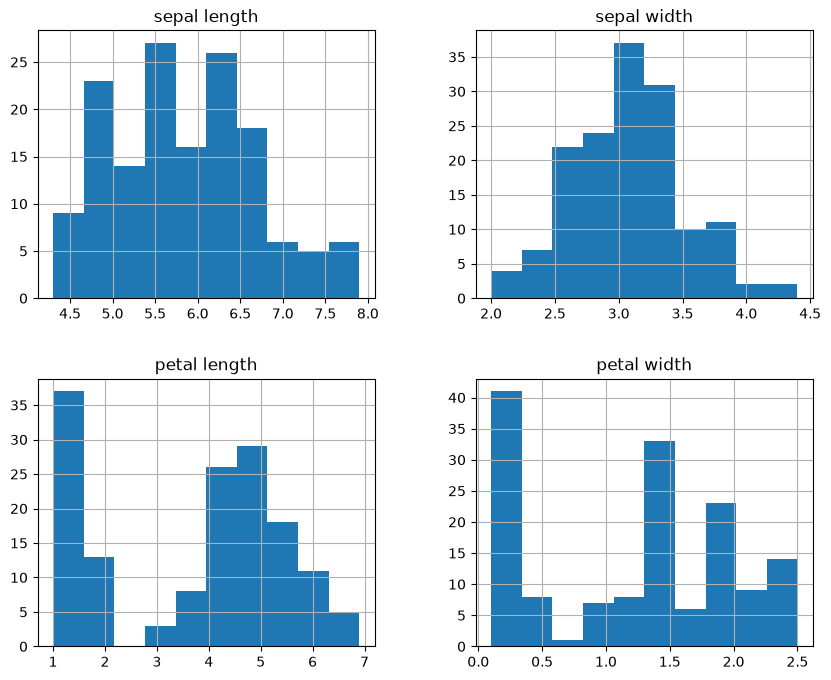

In [8]:
iris.hist(figsize=(10, 8))

<Axes: >

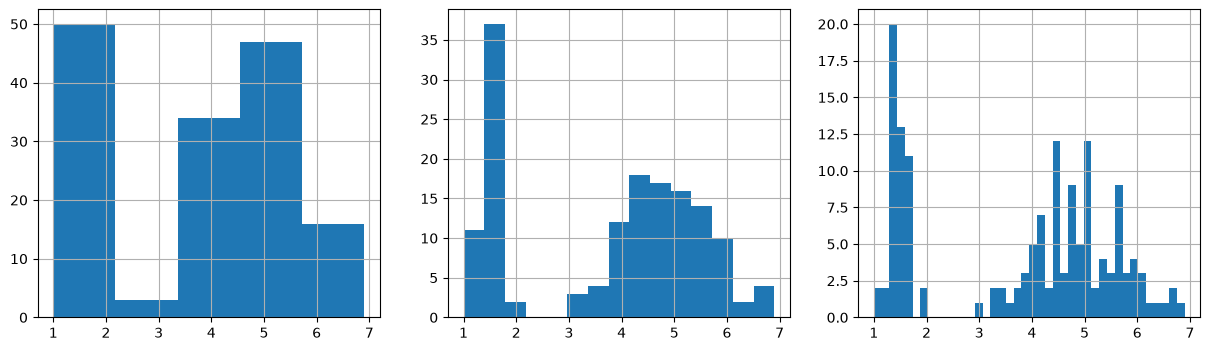

In [9]:
petal_length = iris["petal length"]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), sharey=False)

petal_length.hist(bins=5, ax=axes[0])
petal_length.hist(bins=15, ax=axes[1])
petal_length.hist(bins=40, ax=axes[2])

**Answer**

Yes, in the case of the small bins we can only see the roughly relations/differences from the data but in the bigger bins we can obtain more information from each data since the data will not be flat by the average calculation.

Make a box plot of the numeric features with the `boxplot()` method. The four columns share the same unit (cm), so one plot is fine.

<Axes: >

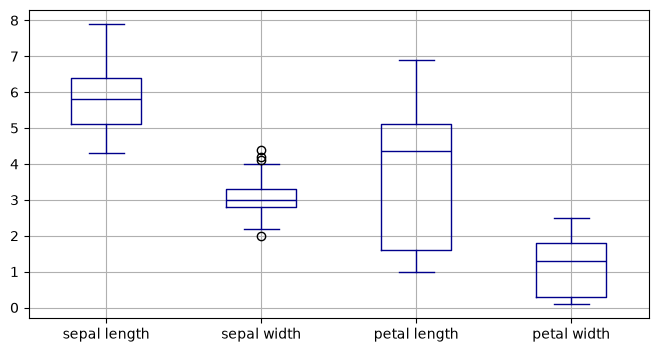

In [10]:
iris.boxplot(color="darkblue")

## A3. Data quality: missing values, impossible values, outliers, duplicates

1. Count the missing values per column (`isna().sum()`). Could you already see it from `describe()`?
1. Are there impossible values (zero or negative lengths)?
1. Count the duplicated rows (`duplicated().sum()`) and show them (`iris[iris.duplicated(keep=False)]`).
1. The box plot of `sepal width` shows a few candidate outliers: are they errors?

In [11]:
print(iris.isna().sum())

impossible_iris = (iris.select_dtypes("number") <= 0).sum().sum()
print("Amount of impossible values = ", impossible_iris)

duplicated_values = iris.duplicated().sum()

print("duplicated rows: ", duplicated_values)

print(iris[iris.duplicated(keep=False)])

sepal length    0
sepal width     0
petal length    0
petal width     0
class           0
dtype: int64
Amount of impossible values =  0
duplicated rows:  1
     sepal length  sepal width  petal length  petal width           class
101           5.8          2.7           5.1          1.9  Iris-virginica
142           5.8          2.7           5.1          1.9  Iris-virginica


**Answer**

The candidate outliers of sepal width are a few flowers with sepals slightly wider or narrower than the rest:
plausible values, *rare but real*, not errors.

## A4. The target: balance

Count the flowers of each class (`value_counts()`). What accuracy would the trivial model
"always predict the most frequent class" obtain?

In [12]:
class_counts = iris["class"].value_counts()
print(class_counts)
print(f"trivial model accuracy: {class_counts.max() / class_counts.sum():.0%}")

class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
trivial model accuracy: 33%


**Answer**

Perfectly balanced 50 flowers per class. The trivial model is right one time in three (33%),
so here accuracy is a meaningful measure

## A5. Each feature × target; correlations; confounders

### Box plots per class

Make a box plot of each feature grouped by class: add the `by` parameter to `boxplot()`.
Then compute the median of each feature per class with `groupby`.

array([[<Axes: title={'center': 'petal length'}, xlabel='[class]'>,
        <Axes: title={'center': 'petal width'}, xlabel='[class]'>],
       [<Axes: title={'center': 'sepal length'}, xlabel='[class]'>,
        <Axes: title={'center': 'sepal width'}, xlabel='[class]'>]],
      dtype=object)

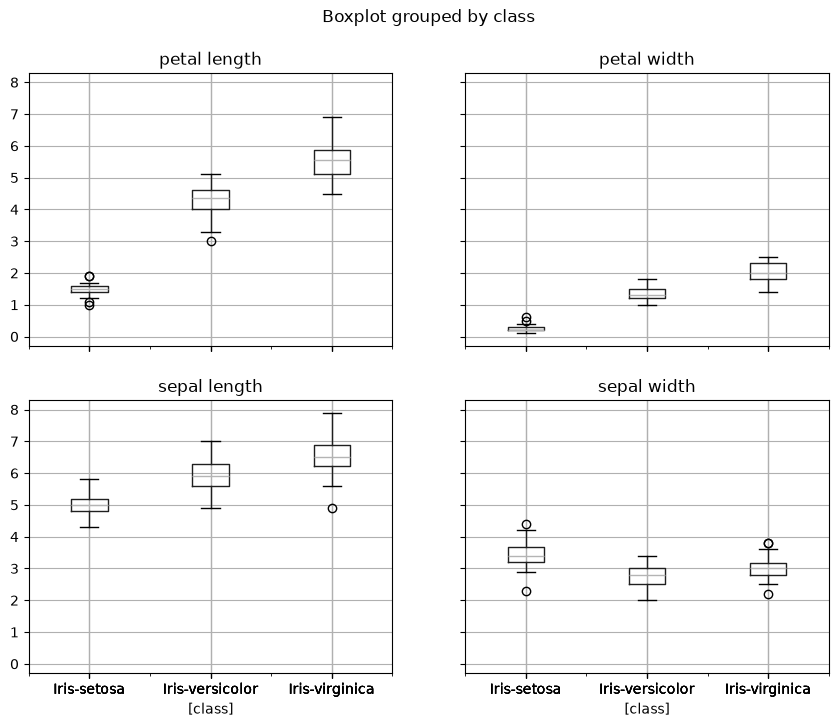

In [13]:
iris.boxplot(by="class", figsize=(10, 8))

In [14]:
iris.groupby("class").median()

,sepal length,sepal width,petal length,petal width
class,,,,
Iris-setosa,5.0,3.4,1.50,0.2
Iris-versicolor,5.9,2.8,4.35,1.3
Iris-virginica,6.5,3.0,5.55,2.0


**Question.** Which features separate the classes best? Which class is easiest to recognize?

**Answer.**

Petal Length and Petal Width

### Pair plot

The [`pairplot`](https://seaborn.pydata.org/generated/seaborn.pairplot.html) of the *seaborn* library shows a scatter plot
for every pair of numeric features, and the distribution of each feature on the diagonal.
Use the target as colour (`hue`), set `height=2` and `diag_kind="kde"`.

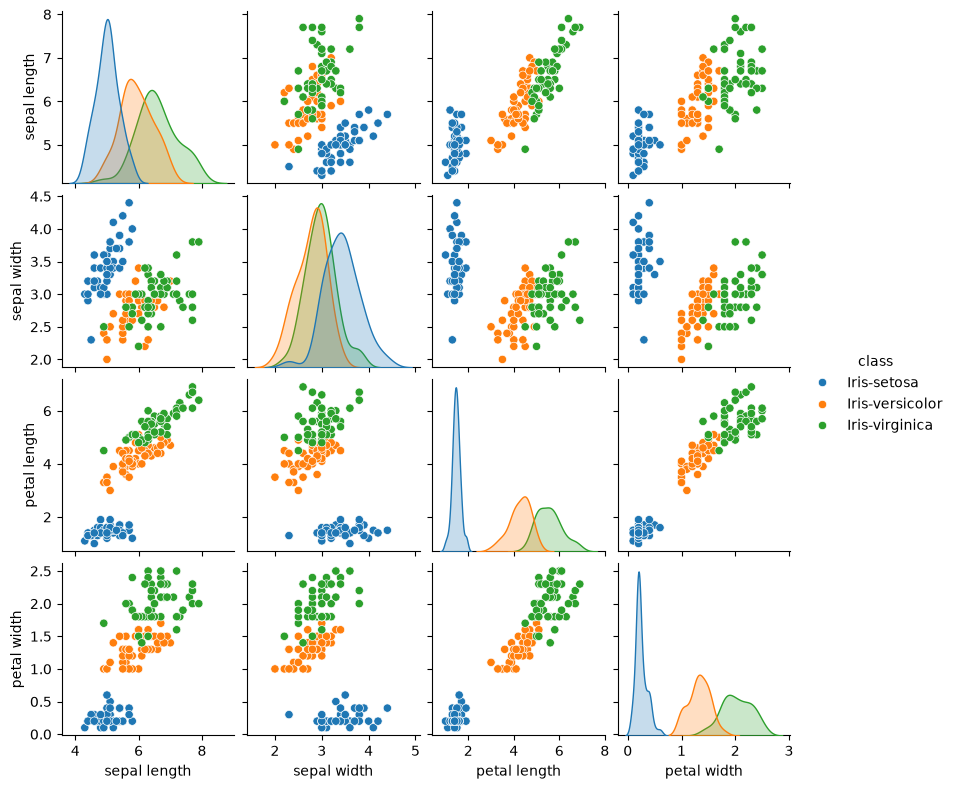

In [15]:
sns.pairplot(data=iris, hue="class", height=2, diag_kind="kde")

### Correlation matrix

Compute the Pearson correlation matrix of the numeric features (`corr(numeric_only=True)`),
then the Spearman one (`method="spearman"`). Show it as a heat map with `sns.heatmap(..., annot=True, vmin=-1, vmax=1, cmap="coolwarm")`.

<Axes: >

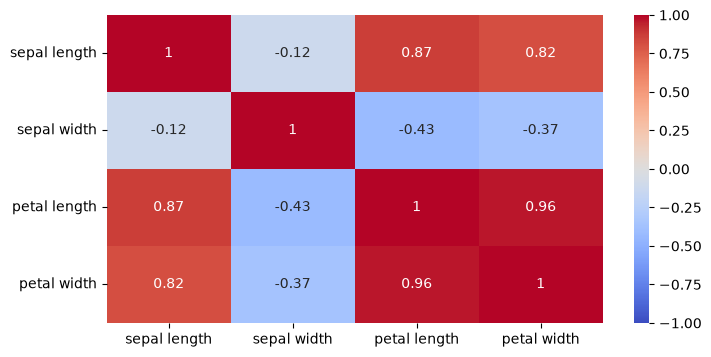

In [16]:
iris_corr = iris.corr(numeric_only=True)
sns.heatmap(data=iris_corr, annot=True, vmin=-1, vmax=1, cmap="coolwarm")

In [17]:
iris.corr(numeric_only=True, method="spearman")

,sepal length,sepal width,petal length,petal width
sepal length,1.00,-0.17,0.88,0.83
sepal width,-0.17,1.00,-0.31,-0.29
petal length,0.88,-0.31,1.00,0.94
petal width,0.83,-0.29,0.94,1.00


### A confounder in Iris ★

Compute the correlation between `sepal length` and `sepal width` on **all** flowers, then **within each class**.
Compare with the scatter plot of the two features in the pair plot. What is happening?

In [18]:
print(f"all flowers: {iris["sepal length"].corr(iris["sepal width"]):.2f}")

for c, g in iris.groupby("class"):
    print(f"{c:16s} {g["sepal length"].corr(g["sepal width"]):.2f}")

all flowers: -0.12
Iris-setosa      0.74
Iris-versicolor  0.53
Iris-virginica   0.46


**Answer.**

On all flowers the correlation is slightly negative (about -0.12); within each species it is clearly positive (about 0.46 ~ .075).

## A6. Findings

Complete the EDA log for Iris (double-click the cell to edit it).

| Finding | Evidence | Decision | Status |
|---|---|---|---|
| 4 ratio features (cm), 1 nominal target, no identifier | `info()` | none | done |
| no missing or impossible values | `isna().sum()`, `describe()` | none | done |
| duplicated rows | `duplicated()` | keep: plausible with 1 mm rounding | noted |
| classes balanced, 50 each | `value_counts()` | accuracy is meaningful here | noted |
| petal features separate the classes; setosa is separable | box plots by class, pair plot | hypothesis for the model | **open** |
| petal length and petal width are strongly correlated (Pearson r ≈ 0.94) | numeric-feature correlation matrix | they may contain overlapping information; check their contribution during modelling | noted |
| sepal length vs width: negative overall, positive within class | correlation per class | species is a confounder | noted |

# Part B — NordicMart customers

The customer table used in Lecture 6: 3000 customers of the NordicMart retail chain, synthetic but realistic,
with the target **churned** (1 = the customer stopped buying). The file is `nordicmart_customers.csv` in your data folder.
Several numbers you compute here appear on the lecture slides: check them.

## B1. Kind of data set and type of every column

Load the file into `df` (the **raw** table: it will not be modified), then show `shape`, `head()` and `info()`.

In [19]:
customer_data = pd.read_csv(NORDICMART_FILE)

print(customer_data.shape)
customer_data.head()

(3000, 9)


,customer_id,tier,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,postcode,churned
0,C-0000,Silver,58.0,27.0,681.03,NaN,0,40100.0,0
1,C-0001,Basic,34.0,95.0,91.08,NaN,0,40100.0,1
2,C-0002,Gold,18.0,37.0,978.61,NaN,0,NaN,0
3,C-0003,Silver,21.0,15.0,973.64,2.0,1,40100.0,0
4,C-0004,Basic,62.0,44.0,213.12,NaN,0,40100.0,0


In [20]:
customer_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          3000 non-null   str    
 1   tier                 3000 non-null   str    
 2   age                  2697 non-null   float64
 3   days_since_last_buy  3000 non-null   float64
 4   annual_spend         3000 non-null   float64
 5   web_sessions_month   2460 non-null   float64
 6   tickets_90d          3000 non-null   int64  
 7   postcode             2777 non-null   float64
 8   churned              3000 non-null   int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 211.1 KB


Count the distinct values of every column with `nunique()`.

**Question.** For every column give the type (identifier, nominal, ordinal, interval, ratio, count, binary target).
Look carefully at `postcode`: which type did pandas give it, and is it right? How many distinct values does it have?

In [21]:
customer_data.nunique()

customer_id            3000
tier                      3
age                      67
days_since_last_buy     247
annual_spend           2959
web_sessions_month       16
tickets_90d               7
postcode                  1
churned                   2
dtype: int64

**Answer.** *Write your answer here (double-click to edit).*

- customer_id: identifier
- tier: ordinal
- age: ratio
- days_since_last_buy: ratio
- annual_spend: ratio
- web_sessions_month: ~~??~~ count
- tickets_90d: ~~ratio~~ count
- postcode: ~~ordinal~~ nominal
- churned: ~~ratio~~ binary target

---

pandas gives **float** to the column of postcode. this is not the right semantic type. A postcode is a nominal code, not a continuous measurement. It has 1 distinct non-missing value in this data set.

Create the **working copy** `customers` on which every fix will be applied, and in it:

1. store `postcode` as text (`astype("string")`, after removing the decimal part) — or simply drop it, since it is constant;
1. make `tier` an *ordered categorical*, so that sorting and plots keep Basic < Silver < Gold:
   `pd.Categorical(..., categories=[...], ordered=True)`.

Keep `customer_id` in the copy for reference, but remember that it is not a feature.

In [22]:
customers = customer_data.copy()
mask = ~customers["postcode"].isna()
postcode  = customers.loc[mask, "postcode"].astype("int").astype("string")[0]

customers = customers.drop(columns=["postcode"])

customers["tier"] = pd.Categorical(customers["tier"], ["Basic", "Silver", "Gold"], ordered=True)

print(customers.dtypes)


customer_id                 str
tier                   category
age                     float64
days_since_last_buy     float64
annual_spend            float64
web_sessions_month      float64
tickets_90d               int64
churned                   int64
dtype: object


## B2. Summaries and one plot per variable

### Summary statistics

Show `describe()` of `annual_spend` and compute the IQR. Is the distribution symmetric?

In [23]:
print(customers["annual_spend"].describe())
q1 = customers["annual_spend"].quantile(0.25)
q3 = customers["annual_spend"].quantile(0.75)
iqr = q3 - q1
print(f"IQR: {iqr}")

count    3000.00
mean      775.38
std       656.09
min        48.51
25%       358.08
50%       569.12
75%       952.14
max      6181.21
Name: annual_spend, dtype: float64
IQR: 594.0625


<Axes: >

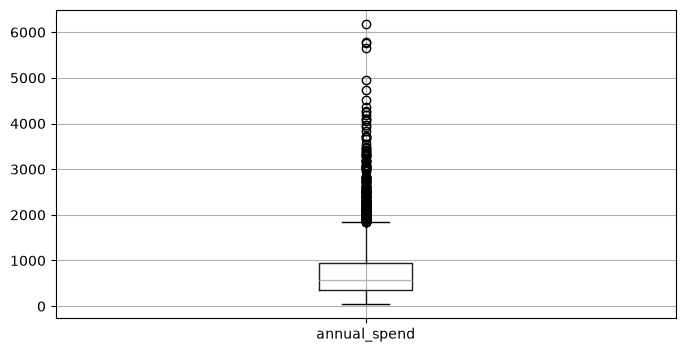

In [24]:
customers.boxplot(column="annual_spend")

**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

The IQR is Q3 − Q1 = 952.14 − 358.08 ≈ 594.06. The distribution is not symmetric; it is right-skewed. The mean (775.38) is higher than the median (569.12), and the maximum value (6181.21) is much larger than Q3, suggesting a long upper tail caused by some high-spending customers.

</font>

### Robust vs non-robust ★

On a **copy** of the spend column, multiply the largest value by 10 (a misplaced decimal point)
and compare mean, std, median and IQR before and after.

In [25]:
before_customer = customers
after_customer  = customers.copy()

mask = after_customer["annual_spend"] == after_customer["annual_spend"].max()

after_customer.loc[mask, "annual_spend"] *= 10

before_customer = before_customer["annual_spend"]
after_customer  = after_customer["annual_spend"]

summary_dict = {
    "max": [before_customer.max(), after_customer.max()],
    "mean": [before_customer.mean(), after_customer.mean()],
    "std": [before_customer.std(), after_customer.std()],
    "median": [before_customer.median(), after_customer.median()],
    "IQR": [before_customer.quantile(0.75) - before_customer.quantile(0.25), after_customer.quantile(0.75) - after_customer.quantile(0.25)]
}

summary_df = pd.DataFrame(summary_dict, index=["original", "max x 10"]).T

print(summary_df)


        original  max x 10
max      6181.21  61812.10
mean      775.38    793.92
std       656.09   1289.42
median    569.12    569.12
IQR       594.06    594.06


**Answer.** *Write your answer here (double-click to edit).*

### Histograms and the bin width

Draw the histogram of `annual_spend` with 8 bins, with 80 bins, and with the Freedman–Diaconis rule (`bins="fd"`).
Then draw it with a logarithmic x axis: use `np.log10(spend)` as data.

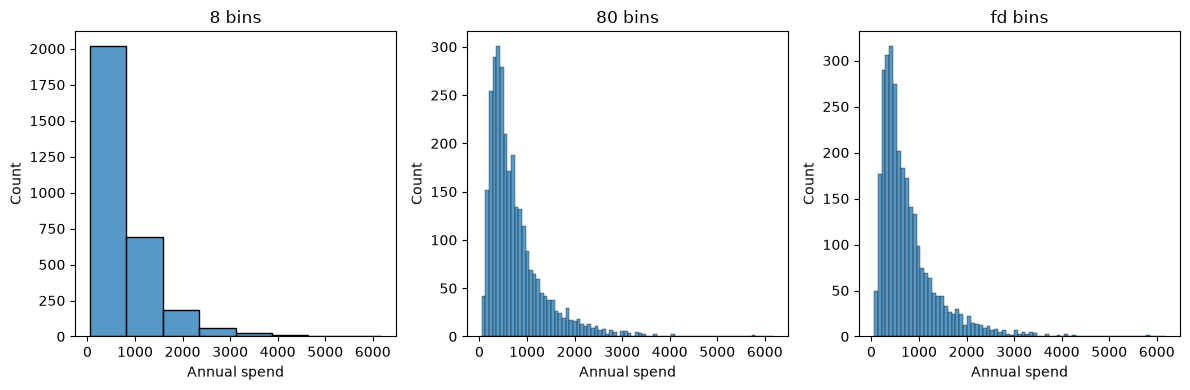

In [26]:
fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize=(12, 4))

annual_spend = customers["annual_spend"]

for ax, bins in zip(axes, [8, 80, "fd"]):
    sns.histplot(data=annual_spend, bins=bins, ax=ax)
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Annual spend")

plt.tight_layout()
plt.show()

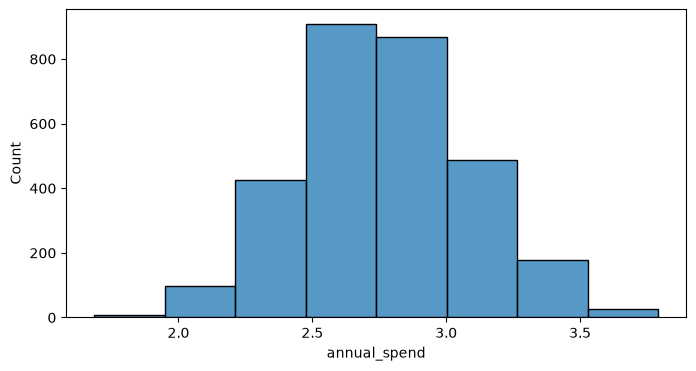

In [27]:
sns.histplot(data=np.log10(annual_spend), bins=8)
plt.show()


### One plot per variable

Draw a histogram of every numeric column (`customers.hist(...)`), and a bar chart of the counts of `tier`
**in the natural order** (`value_counts(sort=False)` on the ordered categorical, then `.plot.bar()`).

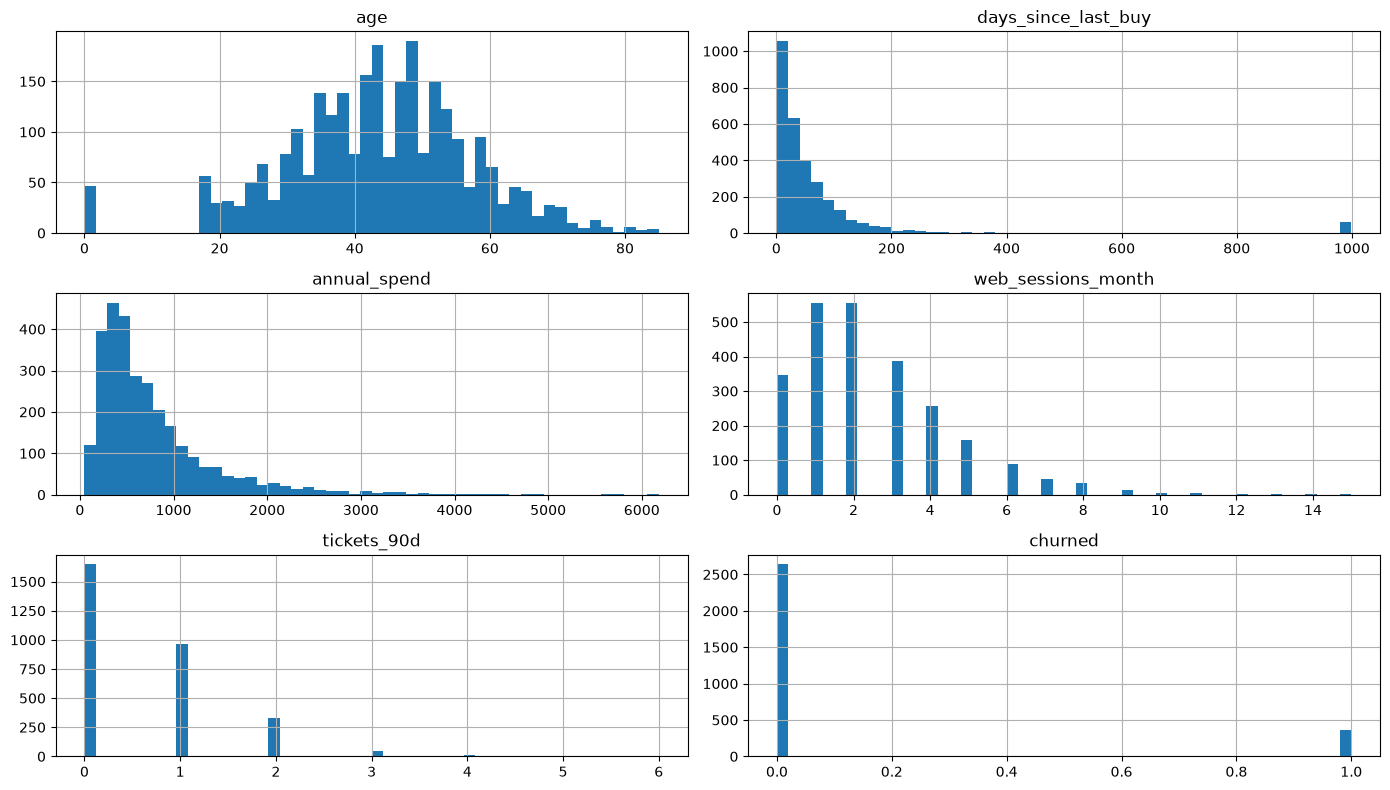

In [28]:
customers.hist(figsize=(14, 8), bins=50)
plt.tight_layout()
plt.show()

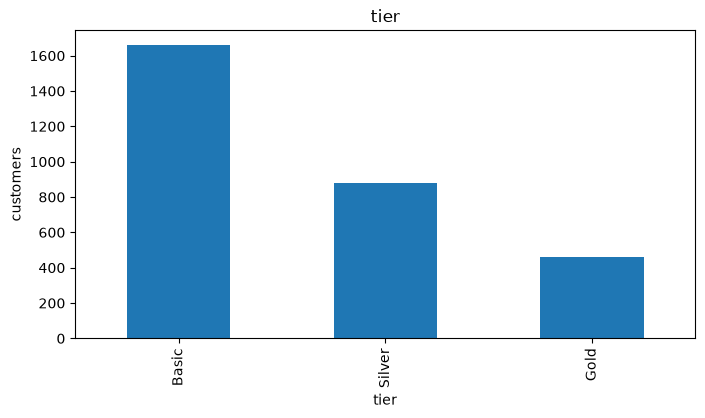

In [29]:
tier = customers["tier"]
tier_counts = tier.value_counts(sort=False)
tier_counts.plot(kind="bar", xlabel="tier", ylabel="customers", title="tier")
plt.show()

**Question.** Look at the histograms: which columns are skewed? Which ones show something strange?

**Answer.** *Write your answer here (double-click to edit).*
<font color="orange" style="font-weight: 700">
There is a right-skewed in the column of **annual_spend**, indicate that the most of the consumption have lower amount of the transaction, so the average is quick higher, but there are several hight transaction on the right side.

There is a strange value 999 on the right side of the column **days_since_last_buy**. I assume that this is not a normal big value. 
</font>

## B3. Data quality

### Codes and defaults that look like numbers

1. Show the most frequent values of `days_since_last_buy` and its maximum. What is 999?
2. How many customers have `age == 0`?
3. In `customers`, recode both as missing (`replace(999, np.nan)`, `replace(0, np.nan)`), **and** keep a flag column
   `never_bought` (1 if the recency was 999).
4. Compare the mean and the median of the recency before and after the recoding.

In [30]:
days_since_last_buy = customers["days_since_last_buy"]
freq  = days_since_last_buy.value_counts()
max_v = days_since_last_buy.max()

print(freq.head())

print(f"max: {max_v} | rows with {max_v}: {freq[max_v]}")

days_since_last_buy
10.0     71
4.0      66
3.0      64
7.0      61
999.0    61
Name: count, dtype: int64
max: 999.0 | rows with 999.0: 61


In [31]:
mask = customers["age"] == 0
amount_of_zero_age = mask.sum()
print(f"amount of zero age = {amount_of_zero_age}")

amount of zero age = 47


In [32]:
customers["age"] = customers["age"].replace(0, np.nan)
never_bought = [True if i == 999 else False for i in customer_data["days_since_last_buy"]]
customers["never_bought"] = never_bought

customers["days_since_last_buy"] = customers["days_since_last_buy"].replace(999, np.nan)
print(f"amount of never bough = {customers["never_bought"].sum()}")


# TEST: test if replace it successfully 
print((customers["days_since_last_buy"].isna()).sum())

amount of never bough = 61
61


In [33]:
mean_value = [customer_data["days_since_last_buy"].mean(), customers["days_since_last_buy"].mean()]
median_value = [customer_data["days_since_last_buy"].median(), customers["days_since_last_buy"].median()]

compare_table = pd.DataFrame({
    "mean": mean_value,
    "median": median_value
}, index=["codes in", "codes out"]).T

compare_table.head()

,codes in,codes out
mean,69.46,50.17
median,34.00,33.00


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">
After removing irrelevant data, we found that the mean changed significantly, but the median remained largely unchanged.
</font>

### Missing values: how many, and why?

1. Compute the percentage of missing values per column in `customers` (`isna().mean()`), and draw it as a horizontal bar chart.
2. Is missingness **informative**? Compare the churn rate of customers with and without `web_sessions_month`,
   and with and without `age`: `customers.groupby(customers["web_sessions_month"].isna())["churned"].mean()`.

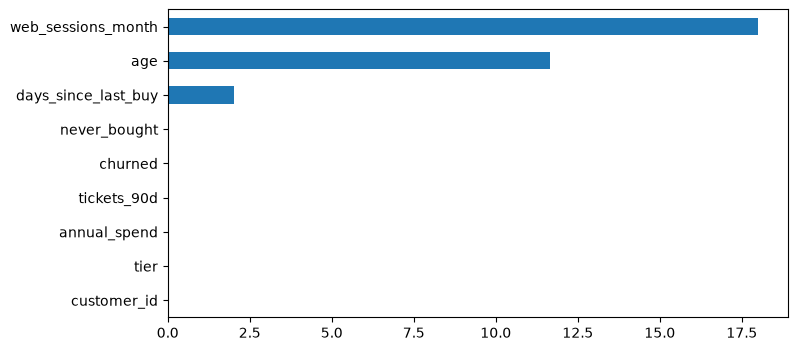

In [34]:
(customers.isna().mean() * 100).sort_values().plot(kind="barh")
plt.show()

In [35]:
group_web_sessions_month = customers.groupby(customers["web_sessions_month"].isna())["churned"].mean() * 100

web_sessions_month = {
    "recorded": round(group_web_sessions_month.to_list()[0], 1),
    "missing": round(group_web_sessions_month.to_list()[1], 1)
}

group_age = customers.groupby(customers["age"].isna())["churned"].mean() * 100

age = {
    "recorded":  round(group_age.to_list()[0], 1),
    "missing":  round(group_age.to_list()[1], 1)
}

print("web_sessions_month", web_sessions_month)

print("age", age)


web_sessions_month {'recorded': 9.6, 'missing': 23.1}
age {'recorded': 11.9, 'missing': 12.6}


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

Customers with missing web_sessions_month have a higher churn rate (23.1%) than customers with recorded values (9.6%), so the missing appears informative and may itself be a useful signal. For age, the churn rates are similar (12.6 % when missing vs 11.9% when recorded), so there is little evidence that age missingness is associated with churn in this data.

</font>


### Outliers: the IQR rule

1. Compute the fences Q1 − 1.5·IQR and Q3 + 1.5·IQR of `annual_spend` and count the customers beyond them.
2. Count the same candidate outliers per tier, and draw a box plot of spend by tier (`customers.boxplot(column=..., by=...)`).
3. Are they errors?

In [36]:
annual_spend = customers["annual_spend"]

IQR = annual_spend.quantile(0.75) - annual_spend.quantile(0.25)

lower_fence = int(annual_spend.quantile(0.25) - 1.5 * IQR)
upper_fence = int(annual_spend.quantile(0.75) + 1.5 * IQR)

mask = (customers["annual_spend"] < lower_fence) | (customers["annual_spend"] > upper_fence)

amount_of_outlier = customers.loc[mask, "annual_spend"].count()

print(f"fences: {lower_fence} ... {upper_fence} | candidate outliers: {amount_of_outlier}")


fences: -533 ... 1843 | candidate outliers: 204


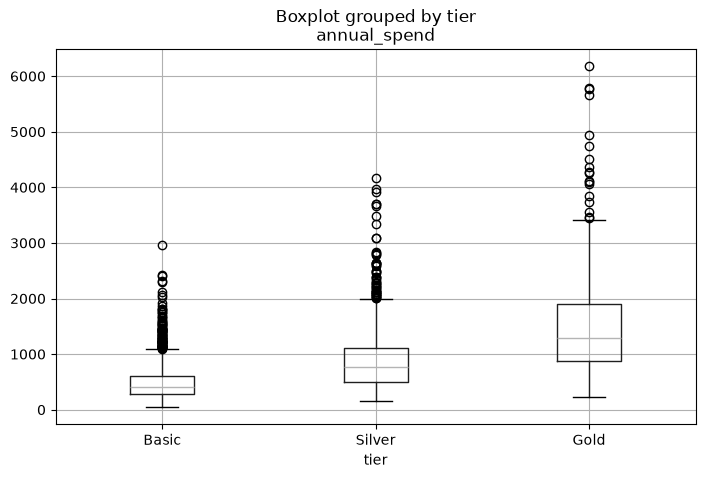

In [37]:
customers.boxplot(column="annual_spend", by="tier", figsize=(8, 5))
plt.show()

In [38]:
# 1. 定義一個用來計算單一群組內離群值的函數
def count_outliers(group):
  Q1 = group.quantile(0.25)
  Q3 = group.quantile(0.75)
  IQR = Q3 - Q1

  lower_fence = Q1 - 1.5 * IQR
  upper_fence = Q3 + 1.5 * IQR

  # 找出這個群組內低於下界或高於上界的人數總和
  is_outlier = (group < lower_fence) | (group > upper_fence)
  return is_outlier.sum()


# 2. 依照 tier 分組，並對 annual_spend 欄位套用這個函數
outliers_by_tier = customers.groupby("tier")["annual_spend"].apply(
    count_outliers
)

print("各個 Tier 的極端客戶數量：")
print(outliers_by_tier)

各個 Tier 的極端客戶數量：
tier
Basic     89
Silver    51
Gold      18
Name: annual_spend, dtype: int64


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

The IQR rule flags some hight-spending customers even within each tier, but this does not mean they are errors. The within-tier outlier rate are about 5.4% for Basic, 5.8% for Silver, and 3.9% for Gold. These may be genuine customers in the upper tail of spending. I would keep then unless checking the source records reveals data-entry errors.

</font>

### Duplicates

Is `customer_id` unique? Are there duplicated rows?

In [39]:
print("duplicated ids: ", customers.duplicated(subset=["customer_id"], keep=False).sum())
subset = customers.columns.to_list()
subset.remove("customer_id")

print("duplicated rows (ignoring the id): ", customers.duplicated(subset=subset, keep=False).sum())

duplicated ids:  0
duplicated rows (ignoring the id):  0


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

No, there's no any duplicated id and row.

</font>

## B4. The target: class imbalance

1. Show the counts and the shares of `churned` (`value_counts(normalize=True)`).
2. The trivial model predicts "stays" (0) for every customer. Show its confusion table with
   `pd.crosstab(actual, predicted)` and compute its accuracy and the number of churners it finds.

In [40]:
print(customers["churned"].value_counts(normalize=False))
print(customers["churned"].value_counts(normalize=True))

churned
0    2640
1     360
Name: count, dtype: int64
churned
0    0.88
1    0.12
Name: proportion, dtype: float64


In [41]:
actual = customers["churned"]
predicted = pd.Series(0, index=actual.index)

display(pd.crosstab(actual, predicted))

accuracy = ( actual == predicted ).mean()
churners_found =( ( actual == 1 ) & ( predicted == 1 )).mean()

print(f"accuracy: {accuracy:.0%} | churners found: {int(churners_found)}")


col_0,0
churned,
0,2640
1,360


accuracy: 88% | churners found: 0


**Answer.** *Write your answer here (double-click to edit).*

## B5. Each feature × target; correlations; confounders

### Numeric × numeric: scatter plot coloured by the target

Scatter plot of `days_since_last_buy` (x) against `annual_spend` (y, log scale), coloured by `churned`.
Against overplotting use small markers and transparency (`alpha`).

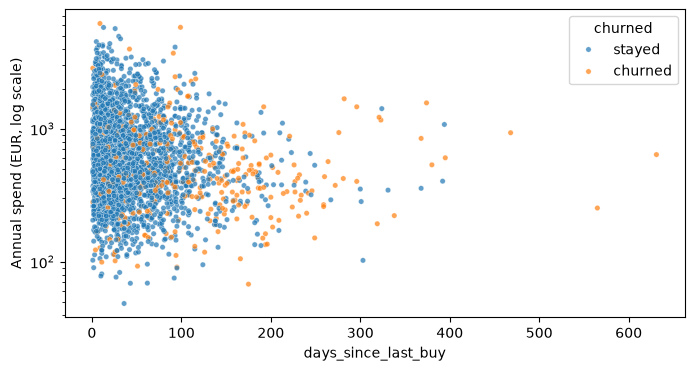

In [42]:
customers_scatter = customers.copy()
# customers_scatter["annual_spend"] = np.log10(customers_scatter["annual_spend"])
customers_scatter["churned"] = customers_scatter["churned"].map(
    {0: "stayed", 1: "churned"}
)

ax = sns.scatterplot(data=customers_scatter, x="days_since_last_buy", y="annual_spend", hue="churned", s=15, alpha=0.7)
ax.set_yscale("log", base=10)
ax.set_ylabel("Annual spend (EUR, log scale)")

plt.show()

### Numeric feature × target: box plots per class

Box plots of `days_since_last_buy` and of `tickets_90d`, grouped by `churned`. Which one looks like a promising feature?

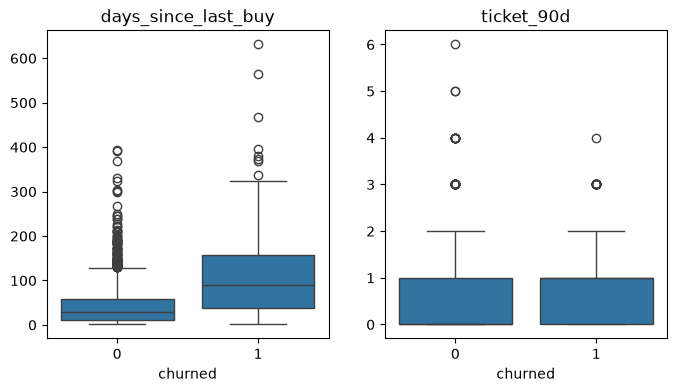

In [43]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))

sns.boxplot(data=customers, x="churned", y="days_since_last_buy", ax=axes[0])
axes[0].set_ylabel("")
axes[0].set_title("days_since_last_buy")

sns.boxplot(data=customers, x="churned", y="tickets_90d", ax=axes[1])
axes[1].set_ylabel("")
axes[1].set_title("ticket_90d")

plt.show()

**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

The feature "days_since_last_buy" looks like a promising feature since the distribution can describe the different between customers who churned and those who stayed. In comparison, tickets_90d shows less separation between the two groups.

</font>

### Categorical feature × target: rates and the cross-table

1. Churn rate per tier (`groupby(...)["churned"].mean()`), as a bar chart with the overall rate as a reference line (`ax.axhline`).
1. The cross-table tier × churned with totals: `pd.crosstab(..., margins=True)`.

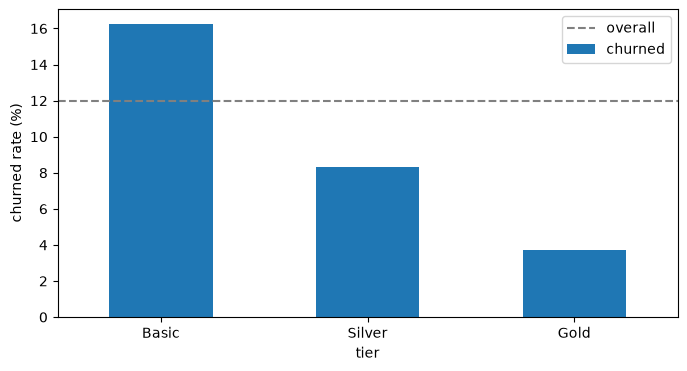

In [44]:
mean_of_churned_by_tier = customers.groupby("tier")["churned"].mean() * 100
overall_rate = customers["churned"].mean() * 100

ax = mean_of_churned_by_tier.plot(kind="bar", label="churned")
ax.axhline(y=overall_rate, linestyle="--", color="gray", label="overall")
ax.tick_params(axis='x', rotation=0)
ax.set_ylabel("churned rate (%)")
ax.legend(loc="upper right")
plt.show()

In [45]:
pd.crosstab(customers["tier"], customers["churned"], margins=True)

churned,0,1,All
tier,,,
Basic,1390,270,1660
Silver,807,73,880
Gold,443,17,460
All,2640,360,3000


**Answer.** *Write your answer here (double-click to edit).*

### Correlation matrix

Pearson correlation matrix of the numeric columns of `customers` (without `customer_id`), as an annotated heat map.
Then compute the Spearman matrix: which pairs change most? Why?

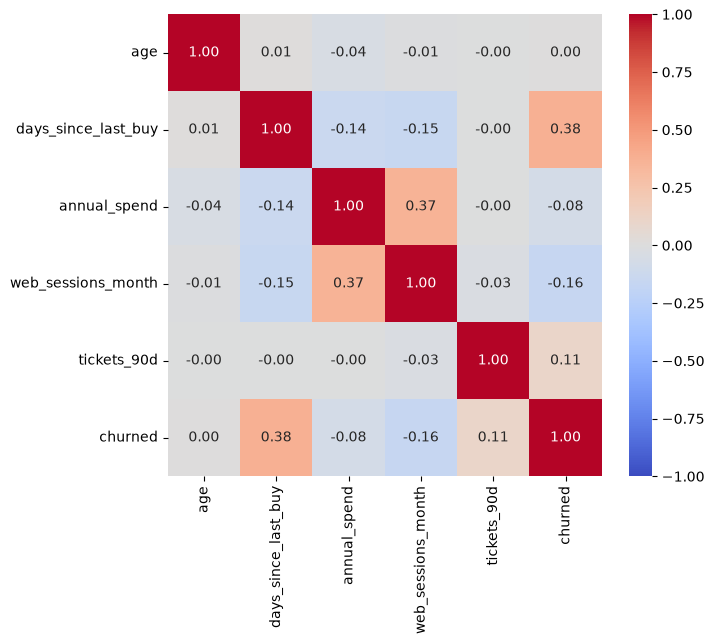

In [46]:
num = customers.drop(columns=["customer_id", "never_bought"]).select_dtypes("number")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(data=num.corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=ax)

plt.show()

In [47]:
spearman_matrix = num.corr(method="spearman")

display((spearman_matrix - num.corr()).round(2))

,age,days_since_last_buy,annual_spend,web_sessions_month,tickets_90d,churned
age,0.00,-0.01,0.02,-0.01,0.01,0.01
days_since_last_buy,-0.01,0.00,-0.00,0.01,-0.01,-0.10
annual_spend,0.02,-0.00,0.00,0.00,-0.02,-0.02
web_sessions_month,-0.01,0.01,0.00,0.00,0.00,-0.01
tickets_90d,0.01,-0.01,-0.02,0.00,0.00,-0.01
churned,0.01,-0.10,-0.02,-0.01,-0.01,0.00


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">

The attribute "days_since_last_buy" and "churned" change mostly since we use the original data in the method of pearson and there's some outliers in the "days_since_last_buy". However, in the method of spearman just focus on the order of the data.

</font>

### Checking a confounder

Spend and web sessions correlate. Do web sessions *cause* spending? Compute the correlation between `annual_spend`
and `web_sessions_month` on all customers, then **within each tier**.

In [48]:
corr_value = customers["annual_spend"].corr(customers["web_sessions_month"])
print(f"all customers: {corr_value:.2f}")

corr_value_group = customers.groupby("tier")["annual_spend"].corr(customers["web_sessions_month"])
print(f"Basic {corr_value_group.Basic:.2f}")
print(f"Silver {corr_value_group.Silver:.2f}")
print(f"Gold {corr_value_group.Gold:.2f}")

all customers: 0.37
Basic 0.04
Silver 0.04
Gold -0.00


**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">


Across all customers, annual_spend and web_sessions_month have a positive correlation of about 0.37. However, within each tier, the correlation is close to zero. This suggests that tier may explain the overall relationship: customers in higher tiers tend to spend more and visit the website more, but the data does not show that more web sessions cause higher spending.

</font>

### Many variables: the pair plot ★

Pair plot of recency, log spend, web sessions and tickets, coloured by `churned`, on a random sample of 900 customers
(`sample(900, random_state=SEED)`). Add a column with `np.log10` of the spend first.
How many panels would you need for 50 features?

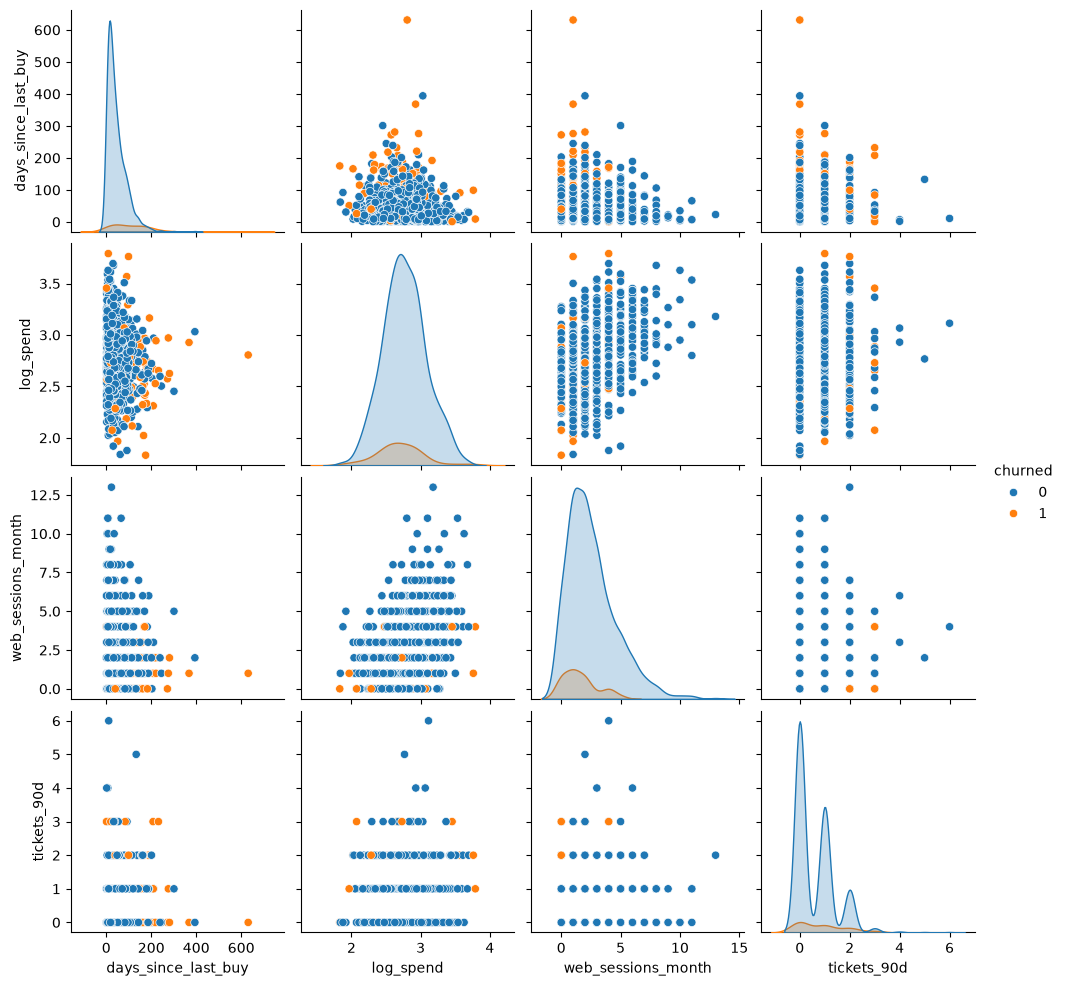

In [49]:
p = customers.dropna(subset=["days_since_last_buy", "web_sessions_month"]).sample(900, random_state=SEED)
p = p.assign(log_spend=np.log10(p["annual_spend"]))
sns.pairplot(data=p[["days_since_last_buy", "log_spend", "web_sessions_month", "tickets_90d", "churned"]], hue="churned")

plt.show()

**Answer.** *Write your answer here (double-click to edit).*

<font color="orange">
We need 50*50 = 2,500 panels to show the relations in the table.
</font>

## B6. Findings → preparation actions

Complete the EDA log for NordicMart. For each finding: the evidence (which plot, which number), the decision, and the status
(*done* if already applied to `customers`, *noted*, or *open* if only the model can answer).

| Finding | Evidence | Decision | Status |
|---|---|---|---|
| `customer_id` is an ID | 3,000 unique values | Exclude before modeling | noted |
| `postcode` is constant | One value + missing values | Drop | done |
| `tier` is ordinal | Basic < Silver < Gold | Encode in order | done |
| Recency 999 means never bought | Histogram; 61 rows | Replace with missing and add a flag | done |
| Age 0 is invalid | Histogram; 47 rows | Replace with missing | done |
| Web-session missingness is informative | 18% missing; churn 23% vs 10% | Keep a missing indicator; don't mean-impute | noted |
| Spend is right-skewed | 204 IQR candidates, mostly Gold | Keep; consider log transform | noted |
| No duplicate rows | `duplicated()` check | No action | done |
| Churn is imbalanced | 12% churn; majority baseline is 88% accurate | Don't rely on accuracy alone | noted |
| Spend and sessions may be confounded by tier | Correlation 0.37 overall; near 0 within tiers | Don't infer causation | noted |
| Recency may predict churn | Box plots; correlation about 0.38 | Validate with a model | open |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw tables `iris` and `df` were never modified: every fix is in `customers`.
1. Save. Keep this notebook: the working copy `customers` and your EDA log are the starting point of the next labs.

In [50]:
# quick self-check: the raw table is untouched
assert (customer_data["days_since_last_buy"] == 999).sum() == 61, "the raw table was modified!"
print("raw table untouched")

raw table untouched
